# 📈 GSK plc (GSK.L) — Comprehensive Fundamental Analysis

**Analyst Skill:** `fundamental-analysis-qwen`  
**Data Sources:** Yahoo Finance (yfinance) + local `output/UK_df.csv`  
**Report Date:** 2026-02-27  

> ⚠️ **Disclaimer:** This report is for educational/research purposes only. Not financial advice. Do your own due diligence before investing.

---

## 0. Setup & Imports

In [3]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
from datetime import datetime, timedelta
from pathlib import Path

# Try plotly for interactive charts; fall back to matplotlib
try:
    import plotly.graph_objects as go
    import plotly.express as px
    from plotly.subplots import make_subplots
    USE_PLOTLY = True
except ImportError:
    USE_PLOTLY = False
    print("plotly not installed — using matplotlib for all charts.")

# ── Constants ──────────────────────────────────────────────────────────────────
TICKER   = 'GSK.L'
NAME     = 'GSK plc'
CURRENCY = 'GBp'   # London prices are in pence; divide by 100 for GBP
PERIOD   = '5y'

plt.style.use('seaborn-v0_8-darkgrid')
pd.set_option('display.float_format', '{:,.4f}'.format)
print(f'Setup complete. Analysing: {NAME} ({TICKER})')

plotly not installed — using matplotlib for all charts.
Setup complete. Analysing: GSK plc (GSK.L)


---
## 1. Company Overview

In [4]:
stock = yf.Ticker(TICKER)
info  = stock.info

overview = {
    'Ticker':          TICKER,
    'Company Name':    info.get('longName', NAME),
    'Sector':          info.get('sector', 'Healthcare'),
    'Industry':        info.get('industry', 'Drug Manufacturers'),
    'Exchange':        info.get('exchange', 'LSE'),
    'Currency':        info.get('currency', 'GBp'),
    'Market Cap (£B)': round(info.get('marketCap', 0) / 1e9, 2),
    'Employees':       f"{info.get('fullTimeEmployees', 'N/A'):,}" if isinstance(info.get('fullTimeEmployees'), int) else 'N/A',
    'Website':         info.get('website', 'N/A'),
    'Current Price':   f"{info.get('currentPrice', info.get('regularMarketPrice', 'N/A'))} GBp",
    '52-Week High':    f"{info.get('fiftyTwoWeekHigh', 'N/A')} GBp",
    '52-Week Low':     f"{info.get('fiftyTwoWeekLow', 'N/A')} GBp",
}

print('\n' + '='*60)
print(f'  {NAME} — COMPANY OVERVIEW')
print('='*60)
for k, v in overview.items():
    print(f'  {k:<25} {v}')
print('='*60)

# Business description
desc = info.get('longBusinessSummary', '')
if desc:
    print(f'\nDescription:\n{desc[:800]}...')


  GSK plc — COMPANY OVERVIEW
  Ticker                    GSK.L
  Company Name              GSK plc
  Sector                    Healthcare
  Industry                  Drug Manufacturers - General
  Exchange                  LSE
  Currency                  GBp
  Market Cap (£B)           88.33
  Employees                 N/A
  Website                   https://www.gsk.com
  Current Price             2201.0 GBp
  52-Week High              2282.0 GBp
  52-Week Low               1242.5 GBp

Description:
GSK plc, together with its subsidiaries, engages in the research, development, and manufacture of vaccines, specialty medicines, and general medicines to prevent and treat disease in the United Kingdom, the United States, and internationally. It operates through Commercial Operations and Total R&D segments. The company offers specialty medicines that include oncology, respiratory/immunology, inflammation, and inhaled medicines for HIV, respiratory eosinophildriven diseases, lupus and lupus 

---
## 2. Technical Analysis

In [5]:
# ── Fetch price history ────────────────────────────────────────────────────────
hist = stock.history(period=PERIOD)
hist.index = pd.to_datetime(hist.index).tz_localize(None)
print(f'Price history loaded: {hist.index[0].date()} → {hist.index[-1].date()} ({len(hist)} trading days)')

# ── Moving Averages ────────────────────────────────────────────────────────────
hist['SMA20']  = hist['Close'].rolling(20).mean()
hist['SMA50']  = hist['Close'].rolling(50).mean()
hist['SMA200'] = hist['Close'].rolling(200).mean()
hist['EMA20']  = hist['Close'].ewm(span=20, adjust=False).mean()

# ── RSI ────────────────────────────────────────────────────────────────────────
delta  = hist['Close'].diff()
gain   = delta.clip(lower=0).rolling(14).mean()
loss   = (-delta.clip(upper=0)).rolling(14).mean()
rs     = gain / loss
hist['RSI'] = 100 - (100 / (1 + rs))

# ── MACD ───────────────────────────────────────────────────────────────────────
ema12          = hist['Close'].ewm(span=12, adjust=False).mean()
ema26          = hist['Close'].ewm(span=26, adjust=False).mean()
hist['MACD']   = ema12 - ema26
hist['Signal'] = hist['MACD'].ewm(span=9, adjust=False).mean()
hist['MACDHist'] = hist['MACD'] - hist['Signal']

# ── Bollinger Bands ────────────────────────────────────────────────────────────
sma20          = hist['Close'].rolling(20).mean()
std20          = hist['Close'].rolling(20).std()
hist['BB_Upper'] = sma20 + 2 * std20
hist['BB_Lower'] = sma20 - 2 * std20

# ── ATR ────────────────────────────────────────────────────────────────────────
high_low   = hist['High'] - hist['Low']
high_close = (hist['High'] - hist['Close'].shift()).abs()
low_close  = (hist['Low']  - hist['Close'].shift()).abs()
tr         = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
hist['ATR'] = tr.rolling(14).mean()

# ── OBV ────────────────────────────────────────────────────────────────────────
obv = [0]
for i in range(1, len(hist)):
    if hist['Close'].iloc[i] > hist['Close'].iloc[i-1]:
        obv.append(obv[-1] + hist['Volume'].iloc[i])
    elif hist['Close'].iloc[i] < hist['Close'].iloc[i-1]:
        obv.append(obv[-1] - hist['Volume'].iloc[i])
    else:
        obv.append(obv[-1])
hist['OBV'] = obv

current_price = hist['Close'].iloc[-1]
sma200_val    = hist['SMA200'].iloc[-1]
rsi_val       = hist['RSI'].iloc[-1]
macd_val      = hist['MACD'].iloc[-1]
signal_val    = hist['Signal'].iloc[-1]

# Trend signal
if current_price > sma200_val:
    trend = '🟢 BULLISH (price above 200-SMA)'
else:
    trend = '🔴 BEARISH (price below 200-SMA)'

print(f'Current Price : {current_price:,.0f} GBp')
print(f'SMA200        : {sma200_val:,.0f} GBp')
print(f'RSI(14)       : {rsi_val:.1f}')
print(f'MACD          : {macd_val:.2f} | Signal: {signal_val:.2f}')
print(f'Trend         : {trend}')

Price history loaded: 2021-03-01 → 2026-02-27 (1262 trading days)
Current Price : 2,201 GBp
SMA200        : 1,656 GBp
RSI(14)       : 56.5
MACD          : 74.64 | Signal: 84.56
Trend         : 🟢 BULLISH (price above 200-SMA)


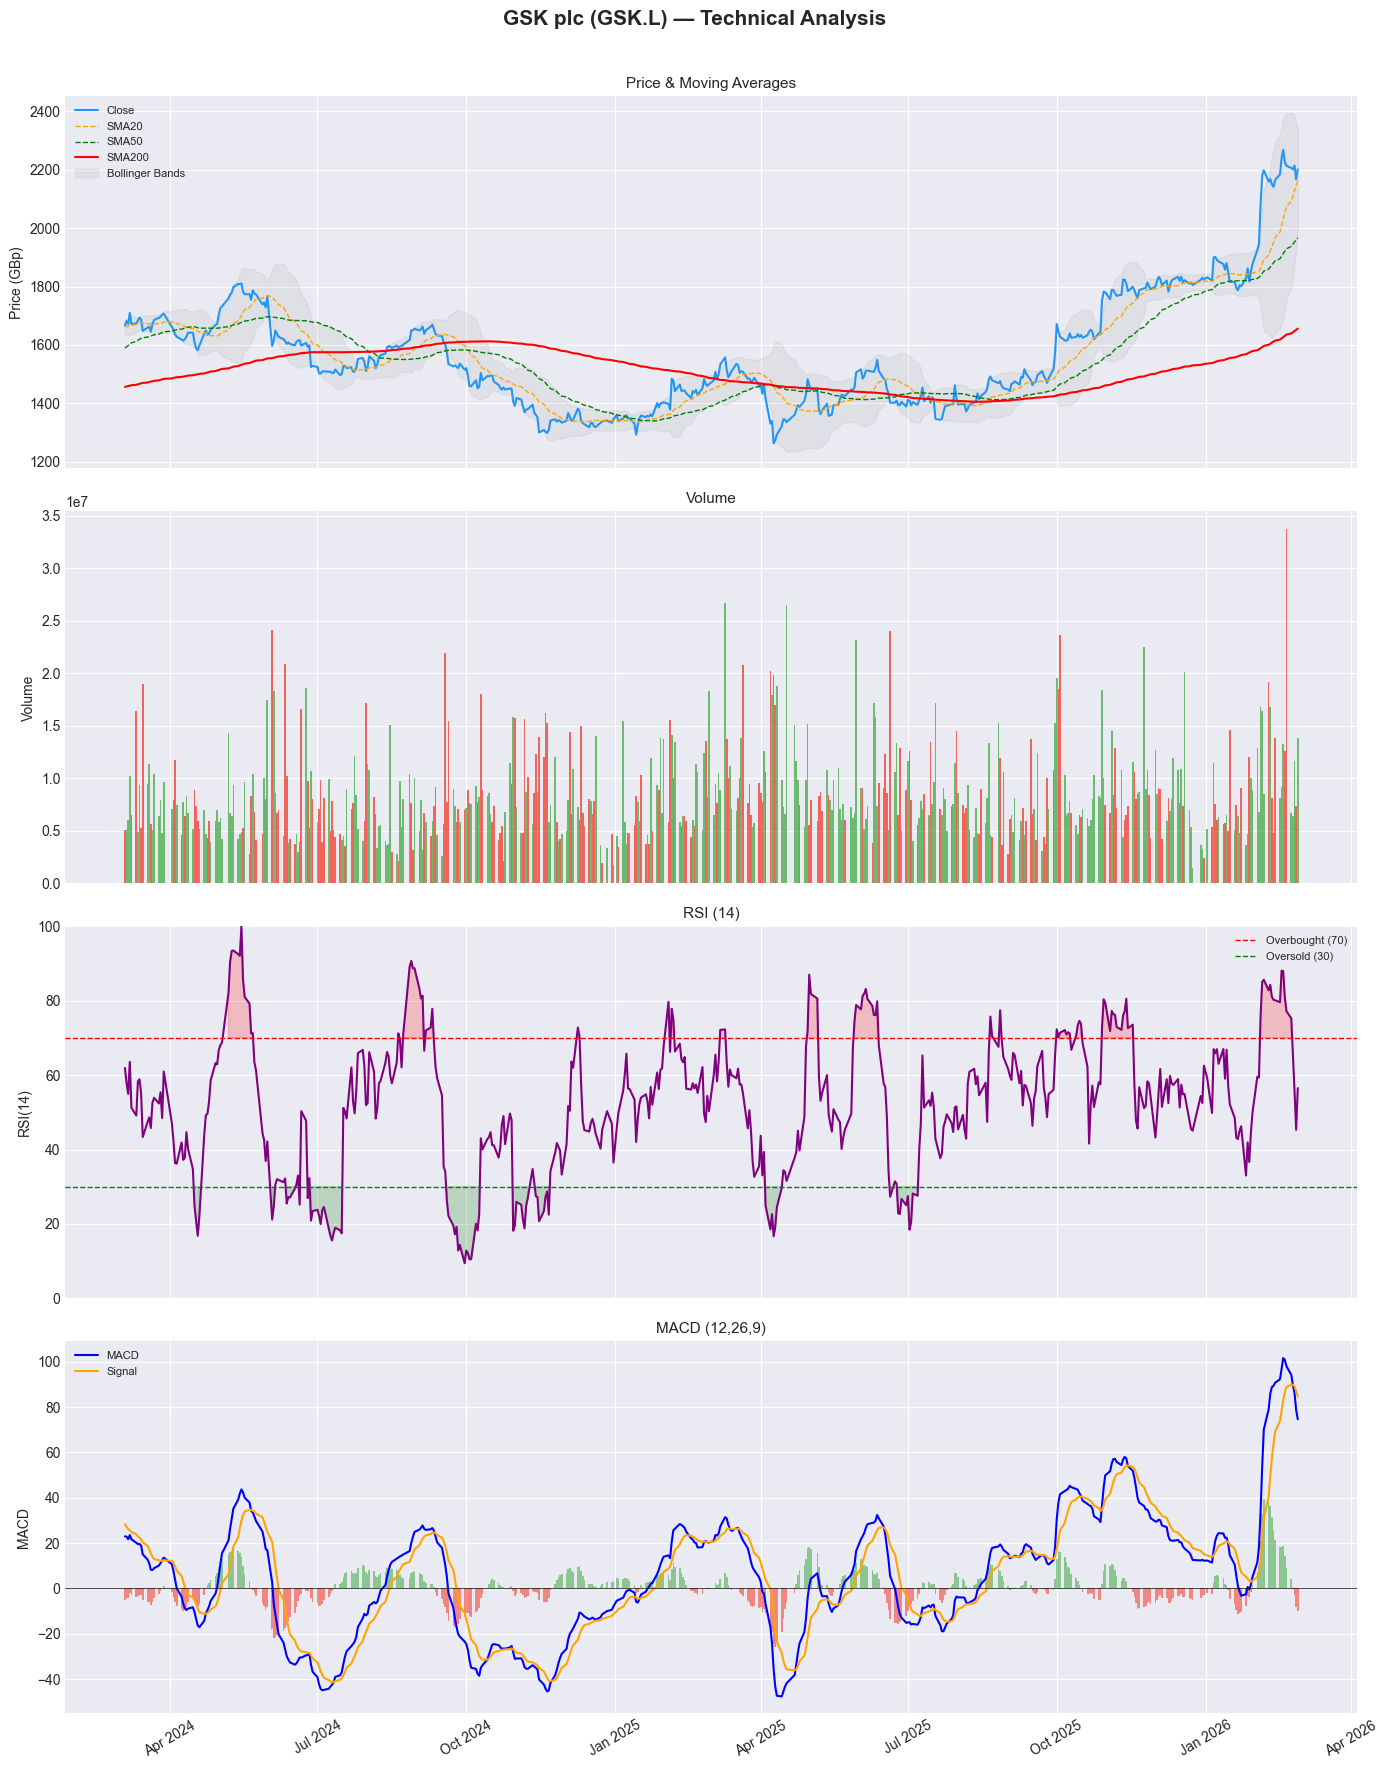

Chart saved: GSK_technical.png


In [8]:
# ── Technical Chart ────────────────────────────────────────────────────────────
recent = hist.tail(504)  # Last 2 years (~252 trading days/year)

fig, axes = plt.subplots(4, 1, figsize=(14, 18), sharex=True)
fig.suptitle(f'{NAME} ({TICKER}) — Technical Analysis', fontsize=15, fontweight='bold', y=0.98)

# Panel 1: Price + MAs + Bollinger Bands
ax1 = axes[0]
ax1.plot(recent.index, recent['Close'],    color='#2196F3', lw=1.5, label='Close')
ax1.plot(recent.index, recent['SMA20'],   color='orange',  lw=1,   label='SMA20', ls='--')
ax1.plot(recent.index, recent['SMA50'],   color='green',   lw=1,   label='SMA50', ls='--')
ax1.plot(recent.index, recent['SMA200'],  color='red',     lw=1.5, label='SMA200')
ax1.fill_between(recent.index, recent['BB_Upper'], recent['BB_Lower'], alpha=0.1, color='gray', label='Bollinger Bands')
ax1.set_ylabel('Price (GBp)')
ax1.legend(loc='upper left', fontsize=8)
ax1.set_title('Price & Moving Averages', fontsize=11)

# Panel 2: Volume
ax2 = axes[1]
colors = ['#4CAF50' if c >= o else '#F44336'
          for c, o in zip(recent['Close'], recent['Open'])]
ax2.bar(recent.index, recent['Volume'], color=colors, width=1, alpha=0.8)
ax2.set_ylabel('Volume')
ax2.set_title('Volume', fontsize=11)

# Panel 3: RSI
ax3 = axes[2]
ax3.plot(recent.index, recent['RSI'], color='purple', lw=1.5)
ax3.axhline(70, color='red',   ls='--', lw=1, label='Overbought (70)')
ax3.axhline(30, color='green', ls='--', lw=1, label='Oversold (30)')
ax3.fill_between(recent.index, recent['RSI'], 70, where=(recent['RSI']>=70), alpha=0.2, color='red')
ax3.fill_between(recent.index, recent['RSI'], 30, where=(recent['RSI']<=30), alpha=0.2, color='green')
ax3.set_ylim(0, 100)
ax3.set_ylabel('RSI(14)')
ax3.legend(fontsize=8)
ax3.set_title('RSI (14)', fontsize=11)

# Panel 4: MACD
ax4 = axes[3]
ax4.plot(recent.index, recent['MACD'],   color='blue',  lw=1.5, label='MACD')
ax4.plot(recent.index, recent['Signal'], color='orange', lw=1.5, label='Signal')
hist_colors = ['#4CAF50' if v >= 0 else '#F44336' for v in recent['MACDHist']]
ax4.bar(recent.index, recent['MACDHist'], color=hist_colors, width=1, alpha=0.6)
ax4.axhline(0, color='black', lw=0.5)
ax4.set_ylabel('MACD')
ax4.legend(fontsize=8)
ax4.set_title('MACD (12,26,9)', fontsize=11)

for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=30)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('GSK_technical.png', dpi=120, bbox_inches='tight')
plt.show()
print('Chart saved: GSK_technical.png')

---
## 3. Fundamental Analysis

> Data sourced from `output/UK_df.csv` (pre-fetched run) + live yfinance supplemental data.

In [9]:
# ── Load from local CSV ────────────────────────────────────────────────────────
csv_path = Path('../output/UK_df.csv')
if not csv_path.exists():
    csv_path = Path('UK_df.csv')  # if running from output/ dir

df_uk = pd.read_csv(csv_path)
gsk_row = df_uk[df_uk['Ticker'] == 'GSK.L'].iloc[0]

# ── Supplemental data from yfinance ───────────────────────────────────────────
pe_ratio   = info.get('trailingPE',    info.get('forwardPE', None))
peg_ratio  = info.get('pegRatio',       None)
pb_ratio   = info.get('priceToBook',    None)
ps_ratio   = info.get('priceToSalesTrailing12Months', None)
ev_ebitda  = info.get('enterpriseToEbitda', None)
div_yield  = info.get('dividendYield',  None)
beta       = info.get('beta',           None)

# ── Display fundamentals table ────────────────────────────────────────────────
fundamentals = {
    '--- VALUATION ---':            '',
    'P/E Ratio (Trailing)':         f"{pe_ratio:.2f}x"    if pe_ratio  else 'N/A',
    'PEG Ratio':                    f"{peg_ratio:.2f}"    if peg_ratio else 'N/A',
    'P/B Ratio':                    f"{pb_ratio:.2f}x"    if pb_ratio  else 'N/A',
    'P/S Ratio':                    f"{ps_ratio:.2f}x"    if ps_ratio  else 'N/A',
    'EV/EBITDA':                    f"{ev_ebitda:.2f}x"   if ev_ebitda else 'N/A',
    '--- PROFITABILITY ---':        '',
    'Gross Margin':                 f"{gsk_row['Gross Margin']*100:.1f}%"    if pd.notna(gsk_row.get('Gross Margin')) else 'N/A',
    'Operating Margin':             f"{gsk_row['Operating Margin']*100:.1f}%" if pd.notna(gsk_row.get('Operating Margin')) else 'N/A',
    'Net Profit Margin':            f"{gsk_row['Net Margin']*100:.1f}%"      if pd.notna(gsk_row.get('Net Margin')) else 'N/A',
    'Return on Assets (ROA)':       f"{gsk_row['Return on Assets']*100:.1f}%" if pd.notna(gsk_row.get('Return on Assets')) else 'N/A',
    'Return on Equity (ROE)':       f"{gsk_row['Return on Equity']*100:.1f}%" if pd.notna(gsk_row.get('Return on Equity')) else 'N/A',
    'Return on Invested Capital':   f"{gsk_row['Return on Invested Capital']*100:.1f}%" if pd.notna(gsk_row.get('Return on Invested Capital')) else 'N/A',
    '--- FINANCIAL HEALTH ---':     '',
    'Debt / Equity':                f"{gsk_row['Debt/Equity']:.1f}" if pd.notna(gsk_row.get('Debt/Equity')) else 'N/A',
    'Current Ratio':                f"{gsk_row['Current Ratio']:.2f}" if pd.notna(gsk_row.get('Current Ratio')) else 'N/A',
    'Quick Ratio':                  f"{gsk_row['Quick Ratio']:.2f}"  if pd.notna(gsk_row.get('Quick Ratio'))  else 'N/A',
    'Interest Coverage':            f"{gsk_row['Interest Coverage']:.2f}x" if pd.notna(gsk_row.get('Interest Coverage')) else 'N/A',
    'Total Assets (£B)':            f"{gsk_row['Total Assets']/1e9:.1f}" if pd.notna(gsk_row.get('Total Assets')) else 'N/A',
    '--- PER SHARE ---':            '',
    'EPS (Trailing)':               f"{gsk_row['EPS']:.2f} GBP" if pd.notna(gsk_row.get('EPS')) else 'N/A',
    'EPS Year-on-Year Growth':      f"+{gsk_row['EPS Year on Year']:.1f}%" if pd.notna(gsk_row.get('EPS Year on Year')) else 'N/A',
    '5-Year Net Income CAGR':       f"{gsk_row['5-Year Net Income %']:.1f}%" if pd.notna(gsk_row.get('5-Year Net Income %')) else 'N/A',
    'Book Value/Share':             f"{gsk_row['Book Value/Share']:.2f} GBP" if pd.notna(gsk_row.get('Book Value/Share')) else 'N/A',
    'Free Cash Flow/Share':         f"{gsk_row['Free Cashflow/Share']:.2f} GBP" if pd.notna(gsk_row.get('Free Cashflow/Share')) else 'N/A',
    '--- INCOME ---':               '',
    'Dividend (Annual)':            f"{gsk_row['Dividends']:.2f} GBP" if pd.notna(gsk_row.get('Dividends')) else 'N/A',
    'Dividend Yield':               f"{div_yield*100:.2f}%" if div_yield else 'N/A',
    'Payout Ratio':                 f"{gsk_row['Payout Ratio']*100:.1f}%" if pd.notna(gsk_row.get('Payout Ratio')) else 'N/A',
    'EBT Margin':                   f"{gsk_row['EBT Margin']*100:.1f}%" if pd.notna(gsk_row.get('EBT Margin')) else 'N/A',
}

print('\n' + '='*55)
print(f'  {NAME} — FUNDAMENTAL METRICS')
print('='*55)
for k, v in fundamentals.items():
    if v == '':
        print(f'  {k}')
        print('  ' + '-'*50)
    else:
        print(f'  {k:<40} {v}')
print('='*55)


  GSK plc — FUNDAMENTAL METRICS
  --- VALUATION ---
  --------------------------------------------------
  P/E Ratio (Trailing)                     15.83x
  PEG Ratio                                N/A
  P/B Ratio                                539.33x
  P/S Ratio                                2.70x
  EV/EBITDA                                7.74x
  --- PROFITABILITY ---
  --------------------------------------------------
  Gross Margin                             72.6%
  Operating Margin                         16.7%
  Net Profit Margin                        17.5%
  Return on Assets (ROA)                   9.8%
  Return on Equity (ROE)                   43.3%
  Return on Invested Capital               N/A
  --- FINANCIAL HEALTH ---
  --------------------------------------------------
  Debt / Equity                            111.1
  Current Ratio                            0.82
  Quick Ratio                              0.52
  Interest Coverage                        N/A
  Total 

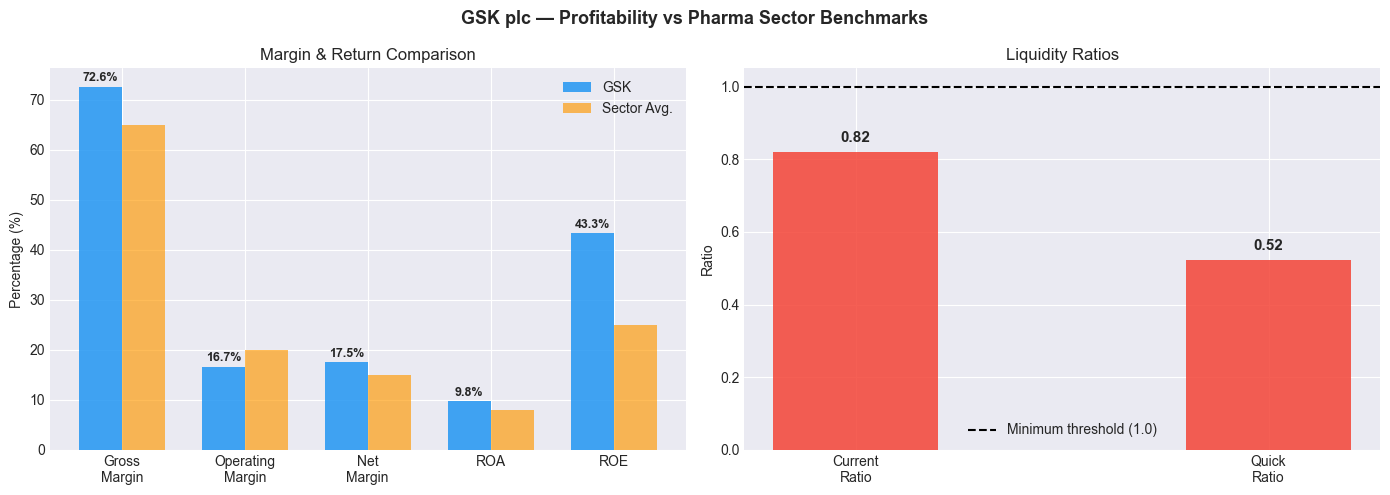

In [10]:
# ── Radar / Bar chart for key margins ─────────────────────────────────────────
margin_labels  = ['Gross\nMargin', 'Operating\nMargin', 'Net\nMargin', 'ROA', 'ROE']
margin_values  = [
    gsk_row['Gross Margin']      * 100 if pd.notna(gsk_row.get('Gross Margin'))      else 0,
    gsk_row['Operating Margin']  * 100 if pd.notna(gsk_row.get('Operating Margin'))  else 0,
    gsk_row['Net Margin']        * 100 if pd.notna(gsk_row.get('Net Margin'))        else 0,
    gsk_row['Return on Assets']  * 100 if pd.notna(gsk_row.get('Return on Assets'))  else 0,
    gsk_row['Return on Equity']  * 100 if pd.notna(gsk_row.get('Return on Equity'))  else 0,
]
# pharma sector benchmarks (approximate)
sector_benchmarks = [65, 20, 15, 8, 25]

x = np.arange(len(margin_labels))
width = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f'{NAME} — Profitability vs Pharma Sector Benchmarks', fontsize=13, fontweight='bold')

bars1 = ax1.bar(x - width/2, margin_values,    width, label='GSK',            color='#2196F3', alpha=0.85)
bars2 = ax1.bar(x + width/2, sector_benchmarks, width, label='Sector Avg.', color='#FF9800', alpha=0.65)
ax1.set_xticks(x)
ax1.set_xticklabels(margin_labels)
ax1.set_ylabel('Percentage (%)')
ax1.set_title('Margin & Return Comparison')
ax1.legend()
for bar in bars1:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Liquidity ratios
ratio_labels = ['Current\nRatio', 'Quick\nRatio']
ratio_values = [
    gsk_row['Current Ratio'] if pd.notna(gsk_row.get('Current Ratio')) else 0,
    gsk_row['Quick Ratio']   if pd.notna(gsk_row.get('Quick Ratio'))   else 0,
]
colors2 = ['#4CAF50' if v >= 1.0 else '#F44336' for v in ratio_values]
bars3 = ax2.bar(ratio_labels, ratio_values, color=colors2, alpha=0.85, width=0.4)
ax2.axhline(1.0, color='black', ls='--', lw=1.5, label='Minimum threshold (1.0)')
ax2.set_ylabel('Ratio')
ax2.set_title('Liquidity Ratios')
ax2.legend()
for bar in bars3:
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('GSK_fundamentals.png', dpi=120, bbox_inches='tight')
plt.show()

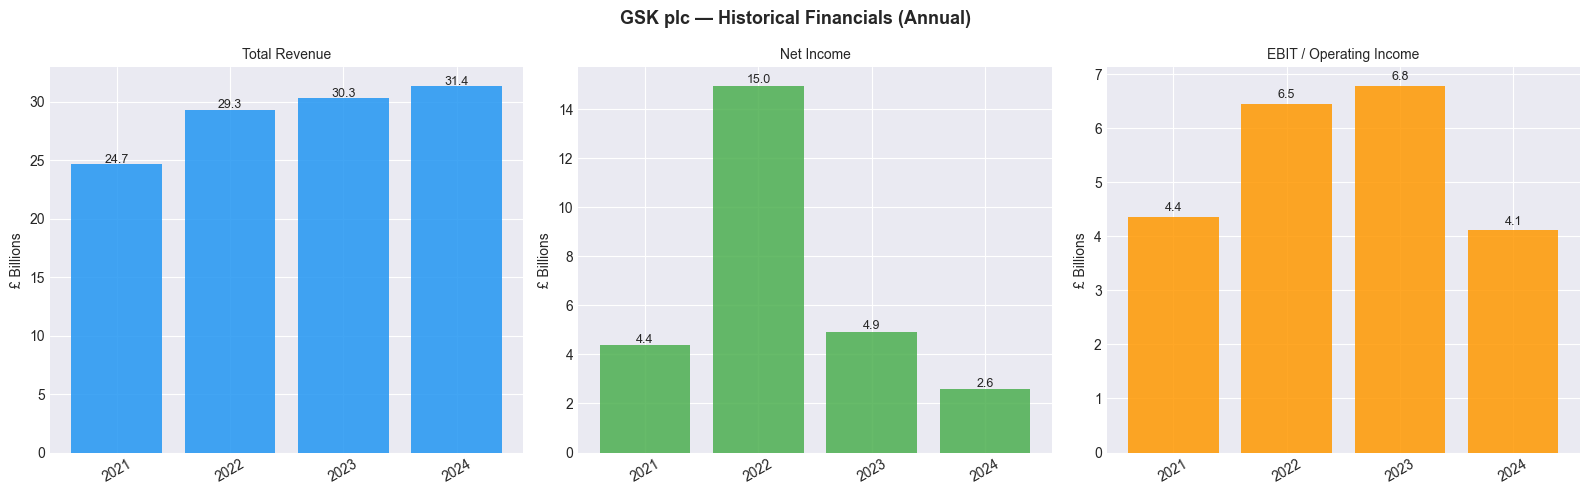

In [11]:
# ── Historical financials from yfinance ───────────────────────────────────────
financials    = stock.financials      # income statement
balance_sheet = stock.balance_sheet
cashflow      = stock.cashflow

if not financials.empty:
    revenue_row   = financials.loc['Total Revenue']   if 'Total Revenue'   in financials.index else None
    net_income_row= financials.loc['Net Income']      if 'Net Income'      in financials.index else None
    ebit_row      = financials.loc['EBIT']            if 'EBIT'            in financials.index else \
                    (financials.loc['Operating Income'] if 'Operating Income' in financials.index else None)

    fig, axes2 = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle(f'{NAME} — Historical Financials (Annual)', fontsize=13, fontweight='bold')

    for ax, row, title, color in zip(
        axes2,
        [revenue_row, net_income_row, ebit_row],
        ['Total Revenue', 'Net Income', 'EBIT / Operating Income'],
        ['#2196F3', '#4CAF50', '#FF9800']
    ):
        if row is not None:
            vals  = row.dropna().sort_index()
            years = [str(d.year) for d in vals.index]
            ax.bar(years, vals.values / 1e9, color=color, alpha=0.85)
            ax.set_title(title, fontsize=10)
            ax.set_ylabel('£ Billions')
            ax.tick_params(axis='x', rotation=30)
            for i, (y, v) in enumerate(zip(years, vals.values / 1e9)):
                ax.text(i, v + 0.1, f'{v:.1f}', ha='center', fontsize=9)
        else:
            ax.text(0.5, 0.5, 'Data unavailable', ha='center', va='center', transform=ax.transAxes)
            ax.set_title(title, fontsize=10)

    plt.tight_layout()
    plt.savefig('GSK_financials.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print('No financial statement data available from yfinance.')

---
## 4. DCF Valuation

Simplified DCF using Free Cash Flow per Share. Assumptions follow a conservative pharma scenario.

In [12]:
# ── DCF Inputs ─────────────────────────────────────────────────────────────────
fcf_per_share = gsk_row['Free Cashflow/Share'] if pd.notna(gsk_row.get('Free Cashflow/Share')) else None
shares        = gsk_row['Shares']              if pd.notna(gsk_row.get('Shares'))              else None

if fcf_per_share is not None:
    # Scenario assumptions
    scenarios = {
        'Bear':  {'growth_rate': 0.02, 'terminal_growth': 0.01, 'wacc': 0.12, 'label': '🔴 Bear'},
        'Base':  {'growth_rate': 0.05, 'terminal_growth': 0.02, 'wacc': 0.09, 'label': '🟡 Base'},
        'Bull':  {'growth_rate': 0.08, 'terminal_growth': 0.025,'wacc': 0.08, 'label': '🟢 Bull'},
    }
    projection_years = 10
    current_price_gbp = hist['Close'].iloc[-1] / 100  # GBp → GBP

    print(f'FCF/Share (base): £{fcf_per_share:.3f}')
    print(f'Current Price   : £{current_price_gbp:.2f} (= {current_price_gbp*100:.0f}p)')
    print(f'\n{"-"*60}')
    print(f'{"Scenario":<10} {"Growth":>8} {"WACC":>8} {"Terminal g":>12} {"Intrinsic £":>14} {"MoS":>8}')
    print(f'{"-"*60}')

    dcf_results = {}
    for name, s in scenarios.items():
        cf = fcf_per_share
        pv = 0
        for yr in range(1, projection_years + 1):
            cf  *= (1 + s['growth_rate'])
            pv  += cf / (1 + s['wacc']) ** yr
        terminal = (cf * (1 + s['terminal_growth'])) / (s['wacc'] - s['terminal_growth'])
        pv_terminal = terminal / (1 + s['wacc']) ** projection_years
        intrinsic = pv + pv_terminal
        margin_of_safety = (intrinsic - current_price_gbp) / intrinsic * 100
        dcf_results[name] = {'intrinsic': intrinsic, 'mos': margin_of_safety}
        print(f"{s['label']:<12} {s['growth_rate']*100:>7.0f}% {s['wacc']*100:>7.0f}% {s['terminal_growth']*100:>11.1f}%  £{intrinsic:>12.2f}  {margin_of_safety:>6.1f}%")

    print(f'{"-"*60}')
    base_intrinsic = dcf_results['Base']['intrinsic']
    verdict = '📉 OVERVALUED' if current_price_gbp > base_intrinsic * 1.1 else \
              '📈 UNDERVALUED' if current_price_gbp < base_intrinsic * 0.9 else '⚖️ FAIRLY VALUED'
    print(f'\nBase Case Verdict: {verdict}')
    print(f'Base Intrinsic: £{base_intrinsic:.2f}  |  Current: £{current_price_gbp:.2f}')
else:
    print('FCF/Share data unavailable — DCF skipped.')

FCF/Share (base): £0.890
Current Price   : £22.01 (= 2201p)

------------------------------------------------------------
Scenario     Growth     WACC   Terminal g    Intrinsic £      MoS
------------------------------------------------------------
🔴 Bear             2%      12%         1.0%  £        8.72  -152.3%
🟡 Base             5%       9%         2.0%  £       16.21   -35.8%
🟢 Bull             8%       8%         2.5%  £       25.49    13.6%
------------------------------------------------------------

Base Case Verdict: 📉 OVERVALUED
Base Intrinsic: £16.21  |  Current: £22.01


In [13]:
if fcf_per_share is not None:
    # ── Sensitivity table: Intrinsic value by growth rate × WACC ──────────────
    growth_rates = [0.01, 0.03, 0.05, 0.07, 0.09]
    wacc_rates   = [0.07, 0.08, 0.09, 0.10, 0.12]

    sensitivity = pd.DataFrame(index=[f'{g*100:.0f}%' for g in growth_rates],
                                columns=[f'{w*100:.0f}%' for w in wacc_rates])
    sensitivity.index.name   = 'Growth \ WACC'

    for g in growth_rates:
        for w in wacc_rates:
            cf = fcf_per_share
            pv = 0
            for yr in range(1, projection_years + 1):
                cf  *= (1 + g)
                pv  += cf / (1 + w) ** yr
            tv  = (cf * 1.02) / (w - 0.02)
            pv += tv / (1 + w) ** projection_years
            sensitivity.loc[f'{g*100:.0f}%', f'{w*100:.0f}%'] = f'£{pv:.2f}'

    print('\nDCF Sensitivity Table (Intrinsic Value in £):')
    print(sensitivity.to_string())
    print(f'\n  Current Price: £{current_price_gbp:.2f}')


DCF Sensitivity Table (Intrinsic Value in £):
                   7%      8%      9%     10%     12%
Growth \ WACC                                        
1%             £16.76  £14.01  £12.05  £10.57   £8.49
3%             £19.67  £16.34  £13.97  £12.19   £9.71
5%             £23.07  £19.06  £16.21  £14.08  £11.11
7%             £27.06  £22.25  £18.83  £16.28  £12.73
9%             £31.72  £25.96  £21.87  £18.82  £14.61

  Current Price: £22.01


---
## 5. Risk Assessment

In [14]:
# ── Quantitative risk metrics ──────────────────────────────────────────────────
returns     = hist['Close'].pct_change().dropna()
ann_vol     = returns.std() * np.sqrt(252)
ann_return  = (hist['Close'].iloc[-1] / hist['Close'].iloc[-252] - 1) if len(hist) >= 252 else None

# Maximum drawdown
rolling_max = hist['Close'].cummax()
drawdown    = (hist['Close'] - rolling_max) / rolling_max
max_drawdown = drawdown.min()

# Sharpe ratio (risk-free ≈ 4.5% UK 10-yr gilt)
risk_free = 0.045
sharpe = (ann_return - risk_free) / ann_vol if ann_return is not None else None

# VaR (95% 1-day)
var_95 = np.percentile(returns, 5)
cvar_95 = returns[returns <= var_95].mean()

# Beta vs FTSE 100
try:
    ftse = yf.download('^FTSE', period=PERIOD, progress=False)['Close']
    ftse.index = pd.to_datetime(ftse.index).tz_localize(None)
    common = hist['Close'].align(ftse, join='inner')
    gsk_ret  = common[0].pct_change().dropna()
    ftse_ret = common[1].pct_change().dropna()
    cov      = np.cov(gsk_ret, ftse_ret)
    beta_calc = cov[0, 1] / cov[1, 1]
except Exception:
    beta_calc = beta  # fall back to yfinance value

print('\n' + '='*50)
print('  RISK METRICS')
print('='*50)
print(f'  Annualised Volatility  : {ann_vol*100:.1f}%')
print(f'  1-Year Return          : {ann_return*100:.1f}%' if ann_return else '  1-Year Return          : N/A')
print(f'  Max Drawdown (5y)      : {max_drawdown*100:.1f}%')
print(f'  Sharpe Ratio           : {sharpe:.2f}' if sharpe else '  Sharpe Ratio           : N/A')
print(f'  VaR (95%, 1-day)       : {var_95*100:.2f}%')
print(f'  CVaR (95%, 1-day)      : {cvar_95*100:.2f}%')
print(f'  Beta (vs FTSE 100)     : {beta_calc:.2f}' if beta_calc else '  Beta                   : N/A')
print('='*50)


  RISK METRICS
  Annualised Volatility  : 21.9%
  1-Year Return          : 48.8%
  Max Drawdown (5y)      : -30.6%
  Sharpe Ratio           : 2.02
  VaR (95%, 1-day)       : -1.94%
  CVaR (95%, 1-day)      : -3.08%
  Beta (vs FTSE 100)     : 0.27


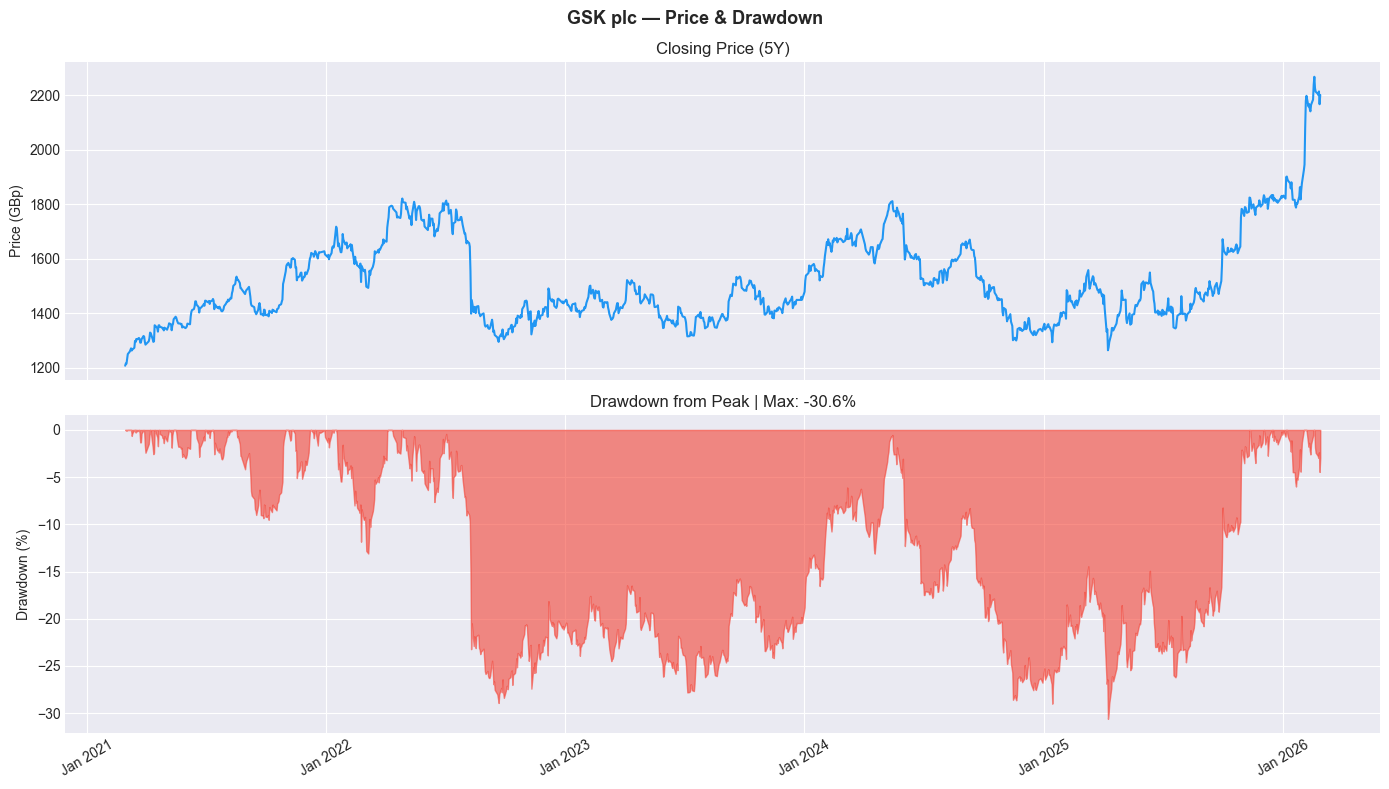


  RED FLAGS CHECKLIST
  --------------------------------------------------
  🔴 CONCERN  Debt/Equity > 2.0 (111.1)
  🔴 CONCERN  Current Ratio < 1.0 (0.82)
  ⚪ N/A  5Y NI Growth < 0%
  🟢 OK  Gross Margin < 40%
  🟢 OK  RSI > 70 (overbought) [57]
  🟢 OK  RSI < 30 (oversold)  [57]
  🔴 CONCERN  MACD bearish crossover
  🟢 OK  Price below SMA200


In [15]:
# ── Drawdown chart ─────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
fig.suptitle(f'{NAME} — Price & Drawdown', fontsize=13, fontweight='bold')

ax1.plot(hist.index, hist['Close'], color='#2196F3', lw=1.5)
ax1.set_ylabel('Price (GBp)')
ax1.set_title('Closing Price (5Y)')

ax2.fill_between(drawdown.index, drawdown.values * 100, 0, color='#F44336', alpha=0.6)
ax2.set_ylabel('Drawdown (%)')
ax2.set_title(f'Drawdown from Peak | Max: {max_drawdown*100:.1f}%')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('GSK_risk.png', dpi=120, bbox_inches='tight')
plt.show()

# ── Red Flags Checklist ────────────────────────────────────────────────────────
de_ratio   = gsk_row['Debt/Equity']   if pd.notna(gsk_row.get('Debt/Equity'))   else 0
curr_ratio = gsk_row['Current Ratio'] if pd.notna(gsk_row.get('Current Ratio')) else 1
ni_growth  = gsk_row['5-Year Net Income %'] if pd.notna(gsk_row.get('5-Year Net Income %')) else None

flags = {
    f'Debt/Equity > 2.0 ({de_ratio:.1f})'   : '🔴 CONCERN'  if de_ratio > 2    else '🟢 OK',
    f'Current Ratio < 1.0 ({curr_ratio:.2f})': '🔴 CONCERN'  if curr_ratio < 1  else '🟢 OK',
    f'5Y NI Growth < 0%'                     : ('🟢 OK' if ni_growth and ni_growth > 0 else '⚪ N/A'),
    'Gross Margin < 40%'                     : '🟢 OK'       if margin_values[0] >= 40  else '🔴 CONCERN',
    f'RSI > 70 (overbought) [{rsi_val:.0f}]' : '🔴 CONCERN'  if rsi_val > 70    else '🟢 OK',
    f'RSI < 30 (oversold)  [{rsi_val:.0f}]'  : '🔵 SIGNAL'   if rsi_val < 30    else '🟢 OK',
    f'MACD bearish crossover'                 : '🔴 CONCERN'  if macd_val < signal_val else '🟢 OK',
    f'Price below SMA200'                     : '🔴 CONCERN'  if current_price < sma200_val else '🟢 OK',
}
print('\n  RED FLAGS CHECKLIST')
print('  ' + '-'*50)
for flag, status in flags.items():
    print(f'  {status}  {flag}')

---
## 6. Peer Comparison

Comparing GSK against key global pharma peers: AstraZeneca (AZN.L), Pfizer (PFE), Johnson & Johnson (JNJ).

In [16]:
peers = {'GSK.L': 'GSK', 'AZN.L': 'AstraZeneca', 'PFE': 'Pfizer', 'JNJ': 'J&J'}

peer_data = []
for ticker_p, name_p in peers.items():
    try:
        i = yf.Ticker(ticker_p).info
        peer_data.append({
            'Company':       name_p,
            'P/E':           round(i.get('trailingPE', float('nan')), 1),
            'P/B':           round(i.get('priceToBook', float('nan')), 2),
            'D/E':           round(i.get('debtToEquity', float('nan')), 1),
            'ROE (%)':       round(i.get('returnOnEquity', 0) * 100, 1),
            'Gross Margin(%)': round(i.get('grossMargins', 0) * 100, 1),
            'Div Yield (%)': round(i.get('dividendYield', 0) * 100, 2),
            'Market Cap (£B)': round(i.get('marketCap', 0) / 1e9, 1),
        })
    except Exception as e:
        print(f'  Could not fetch {ticker_p}: {e}')

df_peers = pd.DataFrame(peer_data).set_index('Company')
print('\nPeer Comparison Table:')
print(df_peers.to_string())


Peer Comparison Table:
                P/E      P/B      D/E  ROE (%)  Gross Margin(%)  Div Yield (%)  Market Cap (£B)
Company                                                                                        
GSK         15.8000 539.3300 111.1000  43.3000          72.6000       332.0000          88.3000
AstraZeneca 32.2000 671.5000  61.0000  22.8000          81.7000       156.0000         241.0000
Pfizer      20.3000   1.6900  66.5000   8.6000          75.8000       635.0000         157.2000
J&J         22.5000   7.3400  60.5000  35.0000          68.1000       214.0000         598.7000


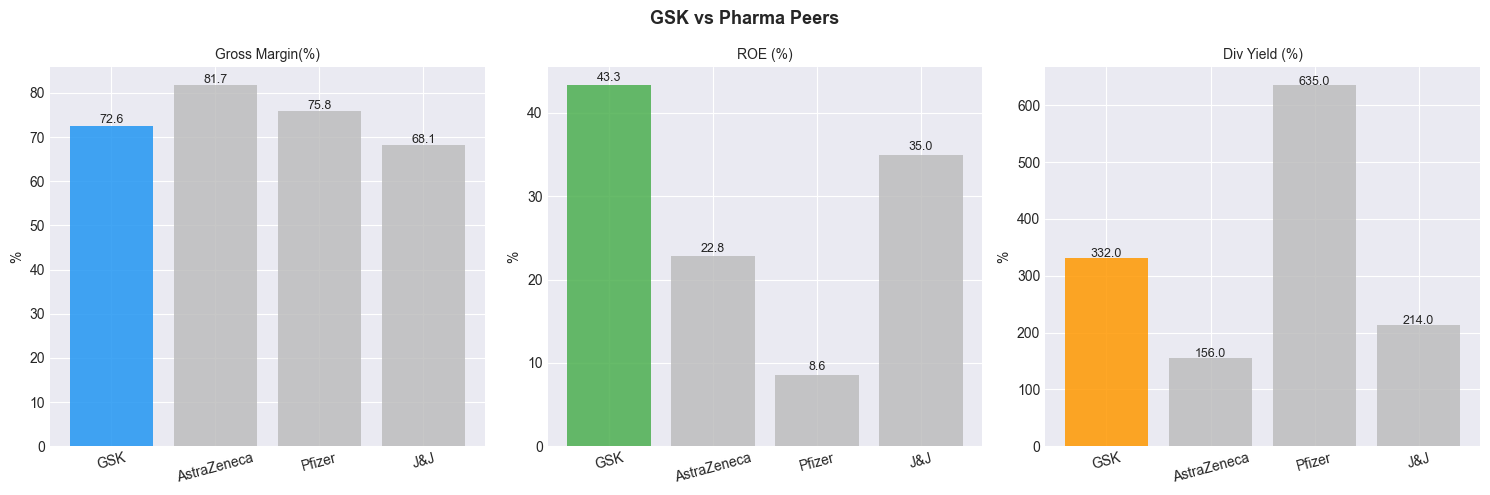

In [17]:
if not df_peers.empty and len(df_peers) > 1:
    fig, axes3 = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle('GSK vs Pharma Peers', fontsize=13, fontweight='bold')

    for ax, col, color in zip(axes3,
                               ['Gross Margin(%)', 'ROE (%)', 'Div Yield (%)'],
                               ['#2196F3', '#4CAF50', '#FF9800']):
        valid = df_peers[col].dropna()
        colors_bar = [color if idx == 'GSK' else '#BDBDBD' for idx in valid.index]
        ax.bar(valid.index, valid.values, color=colors_bar, alpha=0.85)
        ax.set_title(col, fontsize=10)
        ax.set_ylabel('%')
        ax.tick_params(axis='x', rotation=15)
        for i, v in enumerate(valid.values):
            ax.text(i, v + 0.5, f'{v:.1f}', ha='center', fontsize=9)

    plt.tight_layout()
    plt.savefig('GSK_peers.png', dpi=120, bbox_inches='tight')
    plt.show()

---
## 7. Summary & Investment Signals

In [20]:
print('\n' + '='*65)
print(f'  {NAME} ({TICKER}) — INVESTMENT SUMMARY')
print('='*65)

# Score logic: tally bullish vs bearish signals
score = 0

bullish = []
bearish = []

# Profitability
gm = gsk_row['Gross Margin'] * 100 if pd.notna(gsk_row.get('Gross Margin')) else 0
if gm > 65:
    bullish.append(f'✅ Exceptional gross margin {gm:.1f}% — pricing power & patent moat')
    score += 2

roe = gsk_row['Return on Equity'] * 100 if pd.notna(gsk_row.get('Return on Equity')) else 0
if roe > 30:
    bullish.append(f'✅ Strong ROE of {roe:.1f}% — efficient capital deployment')
    score += 1

eps_yoy = gsk_row.get('EPS Year on Year', None)
if pd.notna(eps_yoy) and eps_yoy > 20:
    bullish.append(f'✅ EPS grew {eps_yoy:.0f}% YoY — strong earnings momentum')
    score += 2

fcf_ps = gsk_row.get('Free Cashflow/Share', None)
if pd.notna(fcf_ps) and fcf_ps > 0:
    bullish.append(f'✅ Positive Free Cash Flow/Share (£{fcf_ps:.2f}) — dividend sustainable')
    score += 1

if current_price > sma200_val:
    bullish.append(f'✅ Price ({current_price:.0f}p) above 200-SMA ({sma200_val:.0f}p) — long-term uptrend')
    score += 1

# Risks
de = gsk_row['Debt/Equity'] if pd.notna(gsk_row.get('Debt/Equity')) else 0
if de > 50:
    bearish.append(f'❌ Very high Debt/Equity ratio ({de:.0f}x) — significant leverage risk')
    score -= 3
elif de > 2:
    bearish.append(f'⚠️  Elevated Debt/Equity ({de:.1f}x) — monitor refinancing risk')
    score -= 1

cr = gsk_row['Current Ratio'] if pd.notna(gsk_row.get('Current Ratio')) else 1
if cr < 1.0:
    bearish.append(f'❌ Current Ratio {cr:.2f} < 1.0 — short-term liquidity pressure')
    score -= 2

if rsi_val > 70:
    bearish.append(f'⚠️  RSI {rsi_val:.0f} — overbought territory, potential pullback')
    score -= 1
elif rsi_val < 30:
    bullish.append(f'✅ RSI {rsi_val:.0f} — oversold, potential reversal opportunity')
    score += 1

if macd_val < signal_val:
    bearish.append('⚠️  MACD below signal line — near-term bearish momentum')
    score -= 1
else:
    bullish.append('✅ MACD above signal line — bullish momentum')
    score += 1

bearish.append('⚠️  Pharma pipeline risk — patent cliffs on key drugs (Shingrix, Nucala)')
bearish.append('⚠️  Regulatory risk — drug pricing pressure in US & EU')
score -= 1

print('\n  🟢 BULLISH FACTORS:')
for b in bullish:
    print(f'     {b}')

print('\n  🔴 BEARISH FACTORS / RISKS:')
for b in bearish:
    print(f'     {b}')

# Overall rating
if score >= 4:
    rating = '⭐⭐⭐⭐⭐  STRONG BUY'
elif score >= 2:
    rating = '⭐⭐⭐⭐  BUY'
elif score >= 0:
    rating = '⭐⭐⭐  HOLD'
elif score >= -2:
    rating = '⭐⭐  SELL'
else:
    rating = '⭐  STRONG SELL'

print(f'\n  Overall Signal Score : {score:+d}')
print(f'  OVERALL RATING       : {rating}')

print('\n  KEY LEVELS TO WATCH:')
support    = hist['Low'].tail(63).min()     # Last 3 months (~63 trading days)
resistance = hist['High'].tail(63).max()    # Last 3 months (~63 trading days)
print(f'  Support  (3M low)    : {support:.0f}p')
print(f'  Resistance (3M high) : {resistance:.0f}p')
print(f'  SMA200               : {sma200_val:.0f}p')
print(f'  52W High             : {info.get("fiftyTwoWeekHigh", "N/A")}p')
print(f'  52W Low              : {info.get("fiftyTwoWeekLow",  "N/A")}p')

print('\n' + '='*65)
print('  ⚠️  DISCLAIMER: This is NOT financial advice.')
print('  Past performance does not guarantee future results.')
print('  Always conduct your own research before investing.')
print('='*65)


  GSK plc (GSK.L) — INVESTMENT SUMMARY

  🟢 BULLISH FACTORS:
     ✅ Exceptional gross margin 72.6% — pricing power & patent moat
     ✅ Strong ROE of 43.3% — efficient capital deployment
     ✅ EPS grew 123% YoY — strong earnings momentum
     ✅ Positive Free Cash Flow/Share (£0.89) — dividend sustainable
     ✅ Price (2201p) above 200-SMA (1656p) — long-term uptrend

  🔴 BEARISH FACTORS / RISKS:
     ❌ Very high Debt/Equity ratio (111x) — significant leverage risk
     ❌ Current Ratio 0.82 < 1.0 — short-term liquidity pressure
     ⚠️  MACD below signal line — near-term bearish momentum
     ⚠️  Pharma pipeline risk — patent cliffs on key drugs (Shingrix, Nucala)
     ⚠️  Regulatory risk — drug pricing pressure in US & EU

  Overall Signal Score : +0
  OVERALL RATING       : ⭐⭐⭐  HOLD

  KEY LEVELS TO WATCH:
  Support  (3M low)    : 1769p
  Resistance (3M high) : 2282p
  SMA200               : 1656p
  52W High             : 2282.0p
  52W Low              : 1242.5p

  ⚠️  DISCLAIMER: 

---
## 8. Key Metrics Snapshot Dashboard

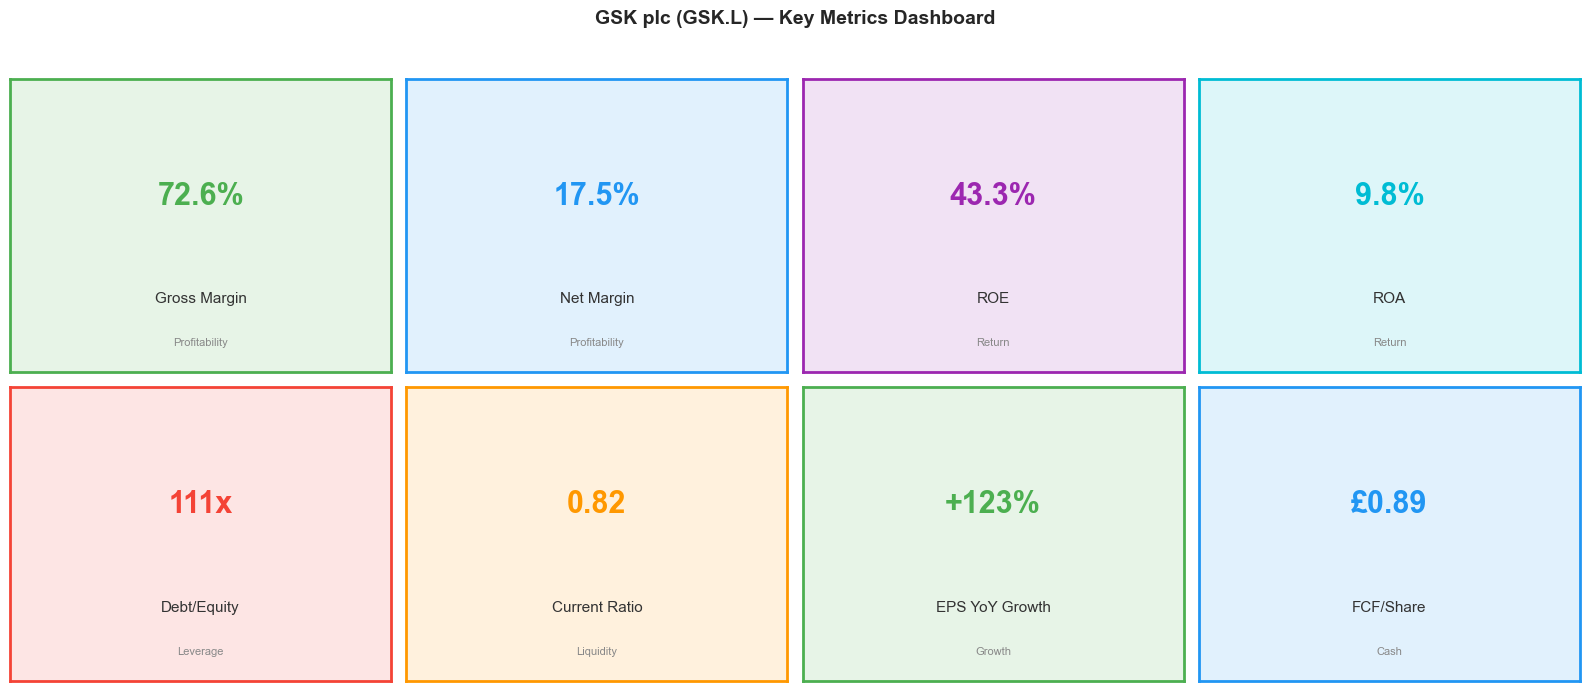


✅ Analysis complete. Charts saved:
   output/GSK_technical.png
   output/GSK_fundamentals.png
   output/GSK_financials.png
   output/GSK_risk.png
   output/GSK_peers.png
   output/GSK_dashboard.png


In [21]:
fig, axes_d = plt.subplots(2, 4, figsize=(16, 7))
fig.suptitle(f'{NAME} ({TICKER}) — Key Metrics Dashboard', fontsize=14, fontweight='bold')
axes_d = axes_d.flatten()

snapshot = [
    ('Gross Margin',     f'{gsk_row["Gross Margin"]*100:.1f}%',      '#4CAF50', 'Profitability'),
    ('Net Margin',       f'{gsk_row["Net Margin"]*100:.1f}%',        '#2196F3', 'Profitability'),
    ('ROE',              f'{gsk_row["Return on Equity"]*100:.1f}%',  '#9C27B0', 'Return'),
    ('ROA',              f'{gsk_row["Return on Assets"]*100:.1f}%',  '#00BCD4', 'Return'),
    ('Debt/Equity',      f'{gsk_row["Debt/Equity"]:.0f}x',          '#F44336', 'Leverage'),
    ('Current Ratio',    f'{gsk_row["Current Ratio"]:.2f}',         '#FF9800' if gsk_row['Current Ratio'] < 1 else '#4CAF50', 'Liquidity'),
    ('EPS YoY Growth',   f'+{gsk_row["EPS Year on Year"]:.0f}%',   '#4CAF50', 'Growth'),
    ('FCF/Share',        f'£{gsk_row["Free Cashflow/Share"]:.2f}',  '#2196F3', 'Cash'),
]

for ax, (label, value, color, category) in zip(axes_d, snapshot):
    ax.set_facecolor(color + '22')
    ax.text(0.5, 0.6, value,    ha='center', va='center', fontsize=22, fontweight='bold', color=color, transform=ax.transAxes)
    ax.text(0.5, 0.25, label,   ha='center', va='center', fontsize=11, color='#333333', transform=ax.transAxes)
    ax.text(0.5, 0.10, category,ha='center', va='center', fontsize=8,  color='#888888', transform=ax.transAxes)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor(color)
        spine.set_linewidth(2)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('GSK_dashboard.png', dpi=120, bbox_inches='tight')
plt.show()
print('\n✅ Analysis complete. Charts saved:')
for f in ['GSK_technical.png', 'GSK_fundamentals.png', 'GSK_financials.png', 'GSK_risk.png', 'GSK_peers.png', 'GSK_dashboard.png']:
    print(f'   output/{f}')